# Topic 1 — Engineering Basics
### 3-hour seminar

This seminar is self-directed: read the explanations, run the cells, and complete every
**Exercise** block before moving on. Work in pairs if that helps you move faster.

**Suggested pacing (3h):**
- 0:00–0:20 - Read through the setup & workflow overview
- 0:20–1:10 - Part 1: NumPy/Pandas warm-up on a dummy dataset
- 1:10–1:20 - Break
- 1:20–2:40 - Part 2: end-to-end mini-pipeline on a real Kaggle dataset (Titanic)
- 2:40–3:00 - Wrap-up questions


## Learning objectives
By the end of this seminar you should be able to:
- Set up a reproducible Python/ML environment (venv or conda, `requirements.txt`)
- Use NumPy arrays and Pandas DataFrames confidently (indexing, filtering, groupby)
- Describe the standard ML workflow: load → explore → split → train → evaluate
- Build and run a minimal end-to-end scikit-learn pipeline


## Required readings
- Raschka & Mirjalili, *Python Machine Learning* — Ch. 1, "Giving Computers the Ability to Learn from Data" (course textbook list)
- Géron, *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow* — Ch. 1, "The Machine Learning Landscape"
- NumPy quickstart: https://numpy.org/doc/stable/user/quickstart.html
- Pandas in 10 minutes: https://pandas.pydata.org/docs/user_guide/10min.html
- scikit-learn "Getting Started": https://scikit-learn.org/stable/getting_started.html


## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

np.random.seed(42)
print("NumPy:", np.__version__, "| Pandas:", pd.__version__)


NumPy: 2.5.4 | Pandas: 3.0.6


---
## Part 1 — Warm-up with a dummy dataset

We'll generate a synthetic "house size vs. price" dataset to practice NumPy/Pandas basics
and preview the full ML workflow before touching real data.


In [2]:
# Synthetic data: house size (sqm) -> price (thousands of euros)
n = 200
size = np.random.normal(90, 30, n).clip(20, 220)
noise = np.random.normal(0, 15, n)
price = 2.5 * size + 20 + noise

df = pd.DataFrame({"size_sqm": size, "price_k_eur": price})
df.head()


,size_sqm,price_k_eur
0,104.901425,287.620372
1,85.852071,243.041945
2,109.430656,309.822409
3,135.690896,375.034270
4,82.975399,206.773456


### Exercise 1.1 — Pandas basics
Using `df`, compute:
1. The mean and median price
2. The number of houses larger than 100 sqm
3. A new column `price_per_sqm`
4. The 5 most expensive houses (sorted)


In [3]:
# 1. mean and median price
print("Mean price:", df["price_k_eur"].mean())
print("Median price:", df["price_k_eur"].median())

# 2. count of houses > 100 sqm
print("Houses > 100 sqm:", (df["size_sqm"] > 100).sum())

# 3. add price_per_sqm column
df["price_per_sqm"] = df["price_k_eur"] / df["size_sqm"]

# 4. top 5 most expensive houses (sorted)
df.sort_values("price_k_eur", ascending=False).head(5)


Mean price: 243.33760482961043
Median price: 250.27407406915734
Houses > 100 sqm: 65


,size_sqm,price_k_eur,price_per_sqm
113,163.897263,441.945803,2.696481
179,171.605075,436.888213,2.545893
106,146.585577,405.628916,2.767182
125,155.713669,391.071343,2.511477
20,133.969463,389.643536,2.908450


### Exercise 1.2 — Visualize
Plot a scatter of `size_sqm` vs `price_k_eur`. Label your axes.

To make a nicer plot with actual axis labels, check out the [seaborn](https://seaborn.pydata.org/) library and use that one instead of pandas primitive built-in visualisations.

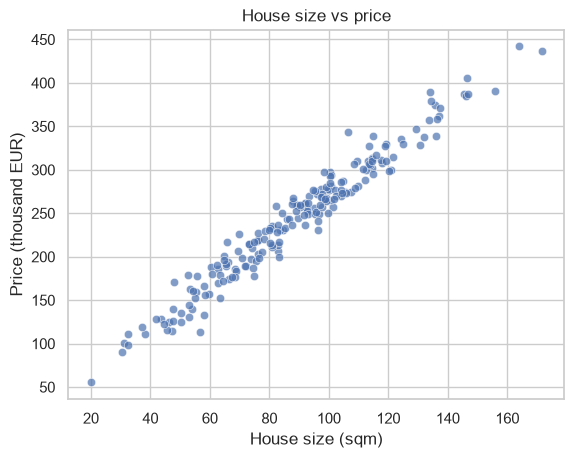

In [4]:
import seaborn as sns
sns.set_theme(style="whitegrid")

sns.scatterplot(data=df, x="size_sqm", y="price_k_eur", alpha=0.7)
plt.xlabel("House size (sqm)")
plt.ylabel("Price (thousand EUR)")
plt.title("House size vs price")
plt.show()


### Mini end-to-end pipeline (worked example)
This previews the full workflow you'll repeat all semester: split → train → evaluate.


In [5]:
X = df[["size_sqm"]].values
y = df["price_k_eur"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
preds = model.predict(X_test)

print("R^2:", r2_score(y_test, preds))
print("RMSE:", np.sqrt(mean_squared_error(y_test, preds)))
print("Learned coefficient:", model.coef_[0], "Intercept:", model.intercept_)


R^2: 0.9399006569697698
RMSE: 16.596408662673632
Learned coefficient: 2.561700332816324 Intercept: 15.697149278590928


---
## Part 2 — Real data: the Titanic dataset (Kaggle)

**Get the data:** https://www.kaggle.com/competitions/titanic/data (or the mirrored dataset
`yasserh/titanic-dataset`). Download `train.csv` and place it next to this notebook, or point
the path below at wherever you saved it.


In [6]:
DATA_PATH = "../data/train.csv"  # Titanic train set, stored under data/
titanic = pd.read_csv(DATA_PATH)
titanic.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Exercise 2.1 — First look
1. Print `.info()` and `.describe()`
2. Which columns have missing values, and how many?
3. What fraction of passengers survived overall?


In [7]:
# 1. .info() and .describe()
titanic.info()
titanic.describe(include="all")

# 2. missing values per column
missing = titanic.isna().sum()
missing[missing > 0].sort_values(ascending=False)

# 3. overall survival rate
print("Survival rate:", titanic["Survived"].mean())


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
Survival rate: 0.3838383838383838


### Exercise 2.2 — Minimal cleaning
1. Fill missing `Age` with the median age
2. Fill missing `Embarked` with the most frequent value
3. Drop the `Cabin` column (too many missing values)
4. One-hot encode `Sex` and `Embarked`


In [8]:
t = titanic.copy()

# 1. fill Age with median
t["Age"] = t["Age"].fillna(t["Age"].median())

# 2. fill Embarked with most frequent value
t["Embarked"] = t["Embarked"].fillna(t["Embarked"].mode()[0])

# 3. drop Cabin
t = t.drop(columns=["Cabin"])

# 4. one-hot encode Sex and Embarked
t = pd.get_dummies(t, columns=["Sex", "Embarked"], drop_first=False)

t.head()


,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,False,True,False,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,True,False,True,False,False
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,True,False,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,True,False,False,False,True
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,False,True,False,False,True


### Exercise 2.3 — Baseline classifier
1. Choose feature columns (e.g. `Pclass`, `Age`, `SibSp`, `Parch`, `Fare`, plus your
   one-hot columns) and target `Survived`
2. Split into train/test (80/20, `random_state=42`)
3. Train a `LogisticRegression`
4. Report accuracy on the test set — how does it compare to always predicting "died"?


In [9]:
features = ["Pclass", "Age", "SibSp", "Parch", "Fare",
            "Sex_male", "Embarked_C", "Embarked_Q", "Embarked_S"]
X = t[features].astype(float)
y = t["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
preds = clf.predict(X_test)

print("LogReg accuracy:", accuracy_score(y_test, preds))

# majority-class baseline (always predict the most common training label)
majority = y_train.mode()[0]
baseline = np.full(len(y_test), majority)
print("Baseline (always", majority, ") accuracy:", accuracy_score(y_test, baseline))

pd.Series(clf.coef_[0], index=features).sort_values(key=abs, ascending=False)


LogReg accuracy: 0.8044692737430168
Baseline (always 0 ) accuracy: 0.6145251396648045


Sex_male     -2.559559
Pclass       -1.091471
Embarked_S   -0.347244
Embarked_Q    0.309282
SibSp        -0.244435
Parch        -0.071256
Age          -0.038550
Embarked_C    0.037655
Fare          0.002235
dtype: float64

---
## Wrap-up questions
1. Why do we split into train/test *before* fitting anything?
2. What would go wrong if we filled missing `Age` using the mean of the *whole* dataset
   (train + test) instead of only the training set?
3. Name one thing you'd want to engineer or investigate further about the Titanic data next time.


---
## Wrap-up answers

1. **Split before fitting** so the test set is truly unseen. Any step that learns from data
   (scaling, imputation, feature selection, model fit) must be fitted on train only; otherwise
   information from the test set leaks in and the score is optimistically biased — it no longer
   estimates performance on new data.
2. **Filling Age with the whole-dataset mean is data leakage**: the imputed value (and any
   statistics derived from it, plus scaling) sneaks test information into training. It also
   makes the test set unrealistically similar to train, so the evaluation is too optimistic.
   Correct way: fit a `SimpleImputer`/median on `X_train` and apply it to `X_test`
   (e.g. inside a `sklearn.pipeline.Pipeline`).
3. Things worth engineering/investigating next:
   - `Name` → title (Mr/Mrs/Miss/Master) and family name → family size / group survival,
     plus `Ticket` prefix and `Cabin` deck letter (Cabin is dropped, but its first letter is
     informative).
   - Age binning (child/adult), `Fare` log-transform, group by `Pclass`.
   - Handle Sex/Embarked/age inside a `Pipeline` + `ColumnTransformer` to avoid leakage, and
     evaluate with cross-validation instead of a single split.
   - Try a tree-based model (RandomForest / GradientBoosting) and compare.
